In [ ]:
# install packages, if necessary (usually only for colab kernel)
import sys
from pathlib import Path

In [ ]:
# if running in Google Colab, install google-colab package and mount Google Drive
if 'google.colab' in sys.modules:
    !pip install google-colab
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = Path("/content/drive/MyDrive/Masterarbeit")  # Ordner nach Wunsch

    !git clone https://github.com/UfukAk196/NO4Cheetah.git
    %cd "Neural Operator for Cheetah/Neural Operator Pipeline"
else:
    OUT_DIR = Path(".")
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
# Install all packages from requirements in NO4Cheetah repo
!pip install -r requirements.txt

In [ ]:
import cheetah
import torch
import neuralop

In [2]:
segment = cheetah.Segment(
    elements=[
        cheetah.Drift(length=torch.tensor(0.175)),
        cheetah.Quadrupole(length=torch.tensor(0.122), name="AREAMQZM1"),
        cheetah.Drift(length=torch.tensor(0.428)),
        cheetah.Quadrupole(length=torch.tensor(0.122), name="AREAMQZM2"),
        cheetah.Drift(length=torch.tensor(0.204)),
        cheetah.VerticalCorrector(length=torch.tensor(0.02), name="AREAMCVM1"),
        cheetah.Drift(length=torch.tensor(0.204)),
        cheetah.Quadrupole(length=torch.tensor(0.122), name="AREAMQZM3"),
        cheetah.Drift(length=torch.tensor(0.179)),
        cheetah.HorizontalCorrector(length=torch.tensor(0.02), name="AREAMCHM1"),
        cheetah.Drift(length=torch.tensor(0.45)),
        cheetah.Screen(name="AREABSCR1"),
    ]
)

In [3]:
segment.AREAMQZM1.k1 = torch.tensor(8.2)
segment.AREAMQZM2.k1 = torch.tensor(-14.3)
segment.AREAMCVM1.angle = torch.tensor(9e-5)
segment.AREAMQZM3.k1 = torch.tensor(3.142)
segment.AREAMCHM1.angle = torch.tensor(-1e-4)

In [4]:
parameter_beam = cheetah.ParameterBeam.from_twiss(beta_x=torch.tensor(3.14))
particle_beam = cheetah.ParticleBeam.from_twiss(
    beta_x=torch.tensor(3.14), beta_y=torch.tensor(42.0), num_particles=10_000
)

In [5]:
outgoing_beam = segment.track(parameter_beam)

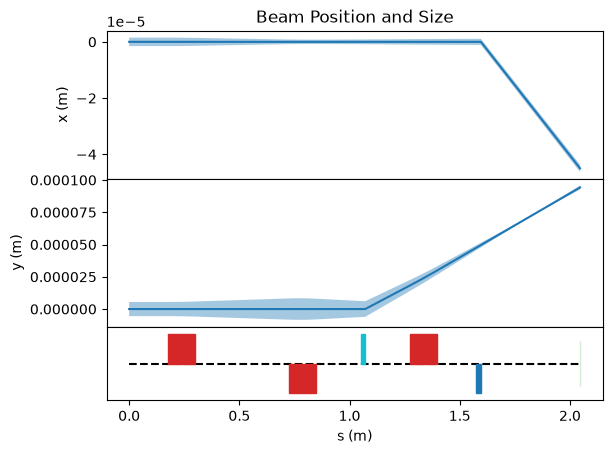

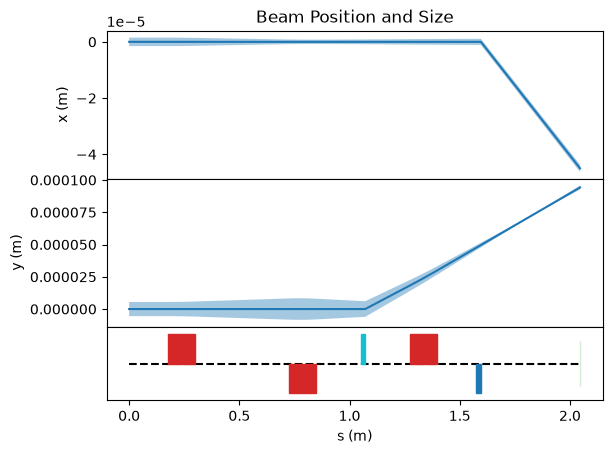

In [6]:
segment.plot_overview(incoming=particle_beam, resolution=0.05)

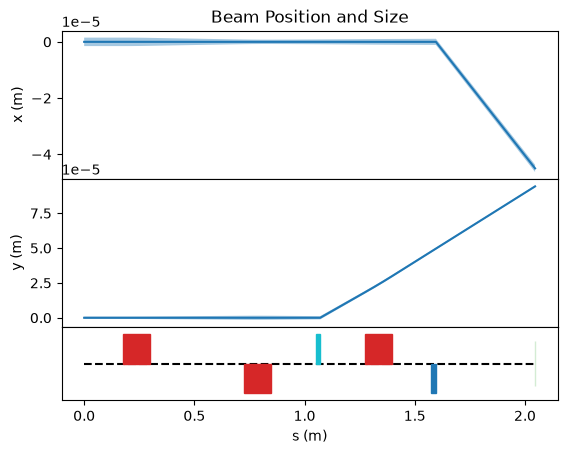

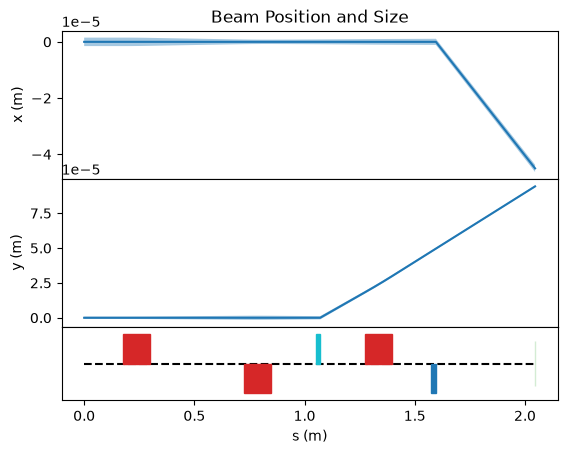

In [7]:
segment.plot_overview(incoming=parameter_beam, resolution=0.05)

---

# Teil 2 — Space-Charge-Kick: was er rechnet und wo das Surrogat einsteigt

Dieser Abschnitt beantwortet drei Fragen direkt am laufenden Code statt auf dem Papier:

| Frage | Wo |
|---|---|
| **Durchsicht 1** — Was rechnet ein Space-Charge-Kick, Schritt für Schritt? | `probe_space_charge` und die Blocktabelle darunter |
| **Durchsicht 3** — An welcher Stelle hänge ich mein eigenes Modell (Neural Operator) ein? | `SurrogateSpaceChargeKick` |
| **Leitfrage 5** — Wie ist das Gleichungssystem für die Simulation mit Space Charge aufgebaut? | Abschnitt „Leitfrage 5" am Ende |

Grundlage: `cheetah/accelerator/space_charge_kick.py` und die Blocktabelle in
`Surrogate Schnittstellen.md`. Kernel: Conda-Env `cheetah` (cheetah 0.8.4, torch 2.14,
CPU). Der Abschnitt läuft in unter einer Minute durch.


In [8]:
import time

import matplotlib.pyplot as plt
from scipy import constants
from scipy.constants import epsilon_0, physical_constants, speed_of_light

from cheetah.utils.cloud_in_cell import cloud_in_cell_charge_deposition

torch.manual_seed(0)

REST_ENERGY = torch.tensor(
    constants.electron_mass * constants.speed_of_light**2 / constants.elementary_charge
)
ELECTRON_RADIUS = torch.tensor(physical_constants["classical electron radius"][0])

print(f"cheetah {cheetah.__version__} | torch {torch.__version__}")
print(f"SpaceChargeKick aus: {cheetah.SpaceChargeKick.__module__}")
print(f"Ruheenergie Elektron: {REST_ENERGY:.6e} eV")


cheetah 0.8.4 | torch 2.14.0+cpu
SpaceChargeKick aus: cheetah.accelerator.space_charge_kick
Ruheenergie Elektron: 5.109989e+05 eV


In [9]:
# Minimales Lattice mit SpaceChargeKick.
# Aufbau uebernommen aus tests/test_space_charge_kick.py::test_cold_uniform_beam_expansion:
# ein kalter, uniform gefuellter Bunch verdoppelt ueber `section_length` seine Groesse.
# Damit ist "einen Kick tracken" nicht nur ausgefuehrt, sondern gegen eine analytische
# Referenz geprueft.

R0 = torch.tensor(0.001)           # Bunchradius im Ruhesystem, m
TOTAL_CHARGE = torch.tensor(1e-8)  # C
ENERGY = torch.tensor(2.5e8)       # eV
NUM_PARTICLES = 100_000

gamma = ENERGY / REST_ENERGY
beta = (1 - gamma.square().reciprocal()).sqrt()

incoming = cheetah.ParticleBeam.uniform_3d_ellipsoid(
    num_particles=NUM_PARTICLES,
    total_charge=TOTAL_CHARGE,
    energy=ENERGY,
    radius_x=R0,
    radius_y=R0,
    radius_tau=R0 / gamma / beta,  # Bunchlaenge im Laborsystem
    sigma_px=torch.tensor(1e-15),  # "kalt": praktisch keine Anfangsdivergenz
    sigma_py=torch.tensor(1e-15),
    sigma_p=torch.tensor(1e-15),
)

kappa = 1 + (torch.tensor(2.0).sqrt() / 4) * (3 + 2 * torch.tensor(2.0).sqrt()).log()
num_electrons = TOTAL_CHARGE / torch.tensor(constants.elementary_charge)
section_length = (
    beta * gamma * kappa * (R0.pow(3) / (num_electrons * ELECTRON_RADIUS)).sqrt()
)

# Kick veraendert nur die Impulse -- die Positionen bewegen die Drifts.
# Deshalb die Verschraenkung Drift / Kick / Drift / Kick / ...
segment_sc = cheetah.Segment(
    elements=[
        cheetah.Drift(section_length / 6),
        cheetah.SpaceChargeKick(section_length / 3, name="SC1"),
        cheetah.Drift(section_length / 3),
        cheetah.SpaceChargeKick(section_length / 3, name="SC2"),
        cheetah.Drift(section_length / 3),
        cheetah.SpaceChargeKick(section_length / 3, name="SC3"),
        cheetah.Drift(section_length / 6),
    ]
)
segment_drift = cheetah.Segment(elements=[cheetah.Drift(section_length)])  # Kontrast

print(f"gamma = {gamma:.2f}, beta = {beta:.9f}")
print(f"section_length = {section_length:.4f} m  (erwartete Verdopplung von sigma)")
print(
    f"Kick: effect_length = {segment_sc.SC1.effect_length:.4f} m"
    f" | grid_shape = {segment_sc.SC1.grid_shape}"
    f" | grid_extent = ({segment_sc.SC1.grid_extent_x:.1f},"
    f" {segment_sc.SC1.grid_extent_y:.1f},"
    f" {segment_sc.SC1.grid_extent_tau:.1f}) sigma"
)


gamma = 489.24, beta = 0.999997914
section_length = 1.8936 m  (erwartete Verdopplung von sigma)
Kick: effect_length = 0.6312 m | grid_shape = (32, 32, 32) | grid_extent = (3.0, 3.0, 3.0) sigma


Tracking mit 3 Kicks: 1504 ms fuer 100000 Teilchen

Groesse              ein      aus (SC)   aus (Drift)    Faktor
--------------------------------------------------------------
sigma_x      4.48331e-04   9.05837e-04   4.48331e-04     2.020
sigma_y      4.47914e-04   9.05704e-04   4.47914e-04     2.022
sigma_tau    9.12710e-07   1.84859e-06   9.12710e-07     2.025
sigma_px     1.00000e-15   3.92819e-04   1.00000e-15 392819212288.000
sigma_py     1.00000e-15   3.93030e-04   1.00000e-15 393029615616.000

Analytische Referenz: Faktor 2 -- gemessen 2.0205 (1.02 % Abweichung, Toleranz 2 %)
Der reine Drift laesst den Strahl unveraendert (kalter Bunch, keine Divergenz).
Alles, was passiert, kommt aus der Raumladung.


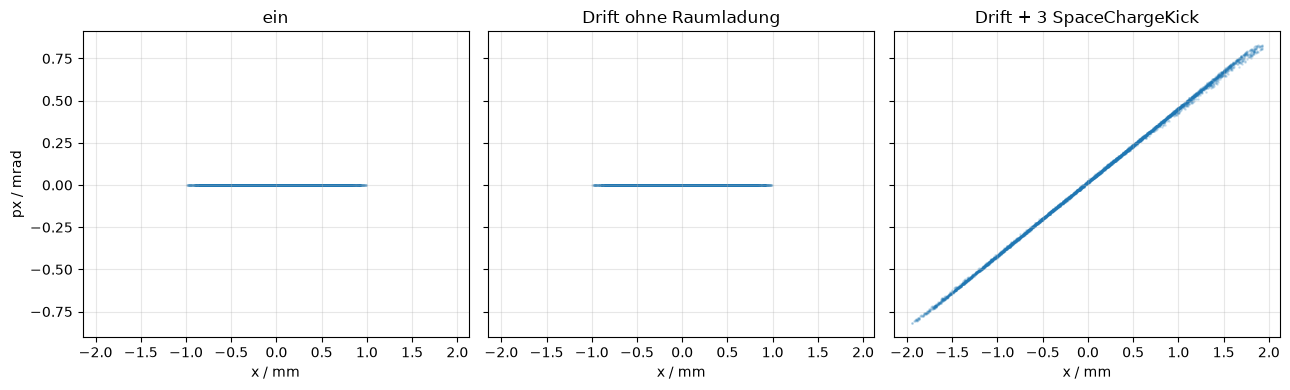

In [10]:
t0 = time.perf_counter()
outgoing = segment_sc.track(incoming)
t_sc = time.perf_counter() - t0
outgoing_drift = segment_drift.track(incoming)

print(f"Tracking mit 3 Kicks: {t_sc * 1e3:.0f} ms fuer {NUM_PARTICLES} Teilchen\n")

head = (
    f"{'Groesse':10s} {'ein':>13s} {'aus (SC)':>13s} {'aus (Drift)':>13s} {'Faktor':>9s}"
)
print(head)
print("-" * len(head))
for name in ["sigma_x", "sigma_y", "sigma_tau", "sigma_px", "sigma_py"]:
    a = getattr(incoming, name)
    b = getattr(outgoing, name)
    c = getattr(outgoing_drift, name)
    print(f"{name:10s} {a:13.5e} {b:13.5e} {c:13.5e} {b / a:9.3f}")

ratio = (outgoing.sigma_x / incoming.sigma_x).item()
print(
    f"\nAnalytische Referenz: Faktor 2 -- gemessen {ratio:.4f}"
    f" ({abs(ratio - 2) / 2 * 100:.2f} % Abweichung, Toleranz 2 %)"
)
print(
    "Der reine Drift laesst den Strahl unveraendert (kalter Bunch, keine Divergenz)."
    "\nAlles, was passiert, kommt aus der Raumladung."
)

fig, axs = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
for ax, beam, title in zip(
    axs,
    [incoming, outgoing_drift, outgoing],
    ["ein", "Drift ohne Raumladung", "Drift + 3 SpaceChargeKick"],
):
    ax.scatter(
        beam.x[::20].detach().numpy() * 1e3,
        beam.px[::20].detach().numpy() * 1e3,
        s=1,
        alpha=0.15,
    )
    ax.set_title(title)
    ax.set_xlabel("x / mm")
    ax.grid(alpha=0.3)
axs[0].set_ylabel("px / mrad")
fig.tight_layout()
plt.show()


## Durchsicht 1 — Was rechnet ein Space-Charge-Kick, Schritt für Schritt?

`SpaceChargeKick.track` ist von außen eine einzige Methode. Innen sind es elf Blöcke,
und die **Aufrufreihenfolge ist der Datenflussrichtung entgegengesetzt**:

```
track → _compute_forces → _E_plus_vB_field → _solve_poisson_equation
        → { _array_rho → cloud_in_cell_charge_deposition,
            _integrated_green_function }
```

`probe_space_charge` unten ruft dieselben Methoden **einzeln** auf, in
Datenflussrichtung, und hält jedes Zwischenprodukt fest. Nichts davon ist nachgebaut —
es sind die Originalmethoden des installierten Cheetah. Die übernächste Zelle belegt
das: das von Hand aus `forces` und `dt` zusammengesetzte Ergebnis ist bitgleich mit
`kick.track(incoming)`.


In [11]:
def probe_space_charge(kick, beam):
    """Calls the blocks of `SpaceChargeKick.track` one by one and records everything.

    Nothing of it is re-implemented: these are the original methods of the
    installed Cheetah, only called in data-flow direction instead of nested. The
    preparation (broadcast, flattening, dt) mirrors `SpaceChargeKick.track`; the
    grid geometry comes from `_grid_geometry`. Only the Hockney zero padding is
    rebuilt for display -- it happens inside `_solve_poisson_on_grid`.
    """
    vector_shape = torch.broadcast_shapes(
        beam.particles.shape[:-2],
        beam.energy.shape,
        beam.particle_charges.shape[:-1],
        beam.survival_probabilities.shape[:-1],
        (1,),
    )
    flat = cheetah.ParticleBeam(
        particles=torch.broadcast_to(
            beam.particles, (*vector_shape, beam.num_particles, 7)
        ).flatten(end_dim=-3),
        energy=torch.broadcast_to(beam.energy, vector_shape).flatten(end_dim=-1),
        particle_charges=torch.broadcast_to(
            beam.particle_charges, (*vector_shape, beam.num_particles)
        ).flatten(end_dim=-2),
        survival_probabilities=torch.broadcast_to(
            beam.survival_probabilities, (*vector_shape, beam.num_particles)
        ).flatten(end_dim=-2),
        species=beam.species,
    )
    effect_length = kick.effect_length.flatten(end_dim=-1)

    # Block 2: grid geometry and time step
    grid_dimensions, cell_size = kick._grid_geometry(flat)
    stretched_cell_size = cell_size.clone()
    stretched_cell_size[:, 2] = stretched_cell_size[:, 2] * flat.relativistic_gamma
    dt = effect_length / (speed_of_light * flat.relativistic_beta)

    # Block 3: s fixed point -> t fixed point
    xp_coordinates = flat.to_xyz_pxpypz()

    # Blocks 4-9
    charge_grid = cloud_in_cell_charge_deposition(
        positions=xp_coordinates[..., [0, 2, 4]],
        bins=kick.grid_shape,
        extent=torch.stack([-grid_dimensions, grid_dimensions], dim=-1),
        charges=flat.particle_charges * flat.survival_probabilities,
    )
    rho = kick._array_rho(flat, xp_coordinates, cell_size, grid_dimensions)
    nx, ny, ntau = kick.grid_shape
    rho_padded = rho.new_zeros((*rho.shape[:-3], 2 * nx, 2 * ny, 2 * ntau))
    rho_padded[..., :nx, :ny, :ntau] = rho  # as in `_solve_poisson_on_grid`
    green = kick._integrated_green_function(stretched_cell_size, kick.grid_shape)
    phi = kick._solve_poisson_equation(flat, xp_coordinates, cell_size, grid_dimensions)
    grad_x, grad_y, grad_tau = kick._E_plus_vB_field(
        flat, xp_coordinates, cell_size, grid_dimensions
    )
    forces = kick._compute_forces(flat, xp_coordinates, cell_size, grid_dimensions)

    return {
        "flat": flat,
        "xp_coordinates": xp_coordinates,
        "grid_dimensions": grid_dimensions,
        "cell_size": cell_size,
        "stretched_cell_size": stretched_cell_size,
        "dt": dt,
        "charge_grid": charge_grid,
        "rho_padded": rho_padded,
        "rho": rho,  # physical octant
        "green": green,
        "phi": phi,
        "grad_x": grad_x,
        "grad_y": grad_y,
        "grad_tau": grad_tau,
        "forces": forces,
        "gamma": flat.relativistic_gamma,
        "beta": flat.relativistic_beta,
    }


kick = segment_sc.SC1
probe = probe_space_charge(kick, incoming)
print("Zwischenprodukte:", ", ".join(probe.keys()))


Zwischenprodukte: flat, xp_coordinates, grid_dimensions, cell_size, dt, charge_grid, rho_padded, rho, green, phi, grad_x, grad_y, grad_tau, forces, gamma, beta


In [12]:
# Die elf Bloecke, aus echten Tensoren -- Gegentest zur Tabelle in
# "Surrogate Schnittstellen.md"
BLOCKS = [
    ("1  track / flatten", "flat", "m, rad", "Batch flachgeklopft"),
    ("2  grid_dimensions", "grid_dimensions", "m", "grid_extent * sigma"),
    ("2  cell_size", "cell_size", "m", "2 * grid_dimensions / grid_shape"),
    ("2  dt", "dt", "s", "effect_length / (beta*c)"),
    ("3  to_xyz_pxpypz", "xp_coordinates", "m, kg m/s", "Spalten 0,2,4 = x,y,tau"),
    ("4  cloud_in_cell", "charge_grid", "C", "trilineare Deposition"),
    ("5  _array_rho", "rho", "C/m^3", "density on the grid"),
    ("6  Hockney pad", "rho_padded", "C/m^3", "2x zero padded"),
    ("6  _green_function", "green", "m^2", "dtau = dz * gamma"),
    ("7  _solve_poisson", "phi", "V", "rfftn(rho)*rfftn(G) -> irfftn"),
    ("8  _E_plus_vB (x)", "grad_x", "V/m", "-1/gamma^2 * dphi/dx"),
    ("8  _E_plus_vB (tau)", "grad_tau", "V/m", "-1/gamma^2 * dphi/dtau"),
    ("9  _compute_forces", "forces", "N", "Rueckinterpolation * e"),
]

head = f"{'Block':22s} {'Form':22s} {'Einheit':11s} {'min':>12s} {'max':>12s}  Anmerkung"
print(head)
print("-" * len(head))
for label, key, unit, note in BLOCKS:
    value = probe[key]
    if isinstance(value, cheetah.ParticleBeam):
        print(
            f"{label:22s} {str(tuple(value.particles.shape)):22s} {unit:11s}"
            f" {'':>12s} {'':>12s}  {note}"
        )
        continue
    print(
        f"{label:22s} {str(tuple(value.shape)):22s} {unit:11s}"
        f" {value.min():12.4e} {value.max():12.4e}  {note}"
    )
print(
    "\n10  Impulsupdate: xp[...,1] += Fx*dt, xp[...,3] += Fy*dt, xp[...,5] += Fz*dt"
    "\n11  from_xyz_pxpypz: zurueck auf s-Fixpunkt, Batch zurueckgeformt"
)


Block                  Form                   Einheit              min          max  Anmerkung
----------------------------------------------------------------------------------------------
1  track / flatten     (1, 100000, 7)         m, rad                                 Batch flachgeklopft
2  grid_dimensions     (1, 3)                 m             2.7381e-06   1.3450e-03  grid_extent * sigma
2  cell_size           (1, 3)                 m             1.7113e-07   8.4062e-05  2 * grid_dimensions / grid_shape
2  dt                  (1,)                   s             2.1055e-09   2.1055e-09  effect_length / (beta*c)
3  to_xyz_pxpypz       (1, 100000, 7)         m, kg m/s    -9.9888e-04   1.0000e+00  Spalten 0,2,4 = x,y,tau
4  cloud_in_cell       (1, 32, 32, 32)        C             0.0000e+00   2.1969e-12  trilineare Deposition
5  _array_rho (pad)    (1, 64, 64, 64)        C/m^3         0.0000e+00   1.8183e+03  Hockney: 2x genullt
5  _array_rho (phys)   (1, 32, 32, 32)        C/m^3

In [13]:
# Zwei Kontrollen, dass der Helper wirklich denselben Pfad laeuft wie `track`

# 1) Ladungserhaltung bei der Deposition
cell_volume = probe["cell_size"].prod(dim=-1)
charge_on_grid = (probe["rho"].flatten(1).sum(dim=1) * cell_volume).item()
print(
    f"Ladung auf dem Gitter: {charge_on_grid:.6e} C von {TOTAL_CHARGE:.6e} C"
    f"  ({charge_on_grid / TOTAL_CHARGE * 100:.3f} % innerhalb +-3 sigma)"
)

# 2) Impulsupdate von Hand -- muss bitgleich zu kick.track(incoming) sein
xp_manual = probe["xp_coordinates"].clone()
for column, component in zip([1, 3, 5], [0, 1, 2]):
    xp_manual[..., column] = (
        xp_manual[..., column]
        + probe["forces"][..., component] * probe["dt"].unsqueeze(-1)
    )
manual = cheetah.ParticleBeam.from_xyz_pxpypz(
    xp_coordinates=xp_manual,
    energy=probe["flat"].energy,
    particle_charges=probe["flat"].particle_charges,
    survival_probabilities=probe["flat"].survival_probabilities,
    s=incoming.s,
    species=incoming.species,
)
reference = kick.track(incoming)
print(
    "Handrechnung == kick.track(incoming):",
    torch.equal(manual.particles.squeeze(0), reference.particles),
)


Ladung auf dem Gitter: 1.000000e-08 C von 1.000000e-08 C  (100.000 % innerhalb +-3 sigma)


Handrechnung == kick.track(incoming): True


In [14]:
# Groessenordnungen von rho und phi -- die Zahlen hinter der Entdimensionalisierung


def describe(name, tensor, unit):
    values = tensor.flatten()
    magnitude = values.abs()
    magnitude = magnitude[magnitude > 0]
    low, high = magnitude.quantile(torch.tensor([0.01, 0.99]))
    decades = (high / low).log10().item()
    print(
        f"{name:10s} {unit:8s} min {values.min():12.4e}  max {values.max():12.4e}"
        f"  Mittel {values.mean():12.4e}  Spanne(P1..P99) {decades:5.1f} Dekaden"
    )


print("Kennzahlen der Felder auf dem 32^3-Gitter:\n")
describe("rho", probe["rho"], "C/m^3")
describe("phi", probe["phi"], "V")
describe("grad_x", probe["grad_x"], "V/m")
describe("grad_tau", probe["grad_tau"], "V/m")
describe("forces", probe["forces"], "N")

phi = probe["phi"]
phi_span = (phi.max() - phi.min()).item()
phi_sphere = (TOTAL_CHARGE / (4 * torch.pi * epsilon_0 * R0)).item()

print(
    f"\nphi traegt einen Offset: min = {phi.min():.4e} V,"
    f" Spannweite = {phi_span:.4e} V."
    "\nDie integrierte Greensche Funktion ist nur bis auf eine Konstante bestimmt --"
    "\nphysikalisch relevant ist ausschliesslich der Gradient. Fuer ein Surrogat heisst"
    "\ndas: Lernziel ist phi ohne Mittelwert, nicht phi."
)
print(
    f"\nAnalytische Referenz: homogen geladene Kugel im Ruhesystem,"
    f" Q/(4 pi eps0 R0) = {phi_sphere:.4e} V."
    f"\nCheetah loest im Laborsystem, wo der Bunch um gamma gestaucht ist -- erwartet"
    f"\nwird also gamma * {phi_sphere:.4e} V = {gamma * phi_sphere:.4e} V."
    f"\nGemessene Spannweite / Erwartung = {phi_span / (gamma * phi_sphere):.3f}"
)


Kennzahlen der Felder auf dem 32^3-Gitter:

rho        C/m^3    min   0.0000e+00  max   1.8183e+03  Mittel   2.5259e+02  Spanne(P1..P99)   4.1 Dekaden
phi        V        min   1.9502e+07  max   6.5692e+07  Mittel   3.6095e+07  Spanne(P1..P99)   0.5 Dekaden
grad_x     V/m      min  -1.7037e+05  max   1.7125e+05  Mittel  -5.3154e+01  Spanne(P1..P99)   1.8 Dekaden
grad_tau   V/m      min  -8.2823e+07  max   8.2574e+07  Mittel  -1.8465e+04  Spanne(P1..P99)   1.8 Dekaden
forces     N        min  -1.3178e-11  max   1.3169e-11  Mittel   1.8515e-13  Spanne(P1..P99)   4.6 Dekaden

phi traegt einen Offset: min = 1.9502e+07 V, Spannweite = 4.6190e+07 V.
Die integrierte Greensche Funktion ist nur bis auf eine Konstante bestimmt --
physikalisch relevant ist ausschliesslich der Gradient. Fuer ein Surrogat heisst
das: Lernziel ist phi ohne Mittelwert, nicht phi.

Analytische Referenz: homogen geladene Kugel im Ruhesystem, Q/(4 pi eps0 R0) = 8.9876e+04 V.
Cheetah loest im Laborsystem, wo der Bunch um

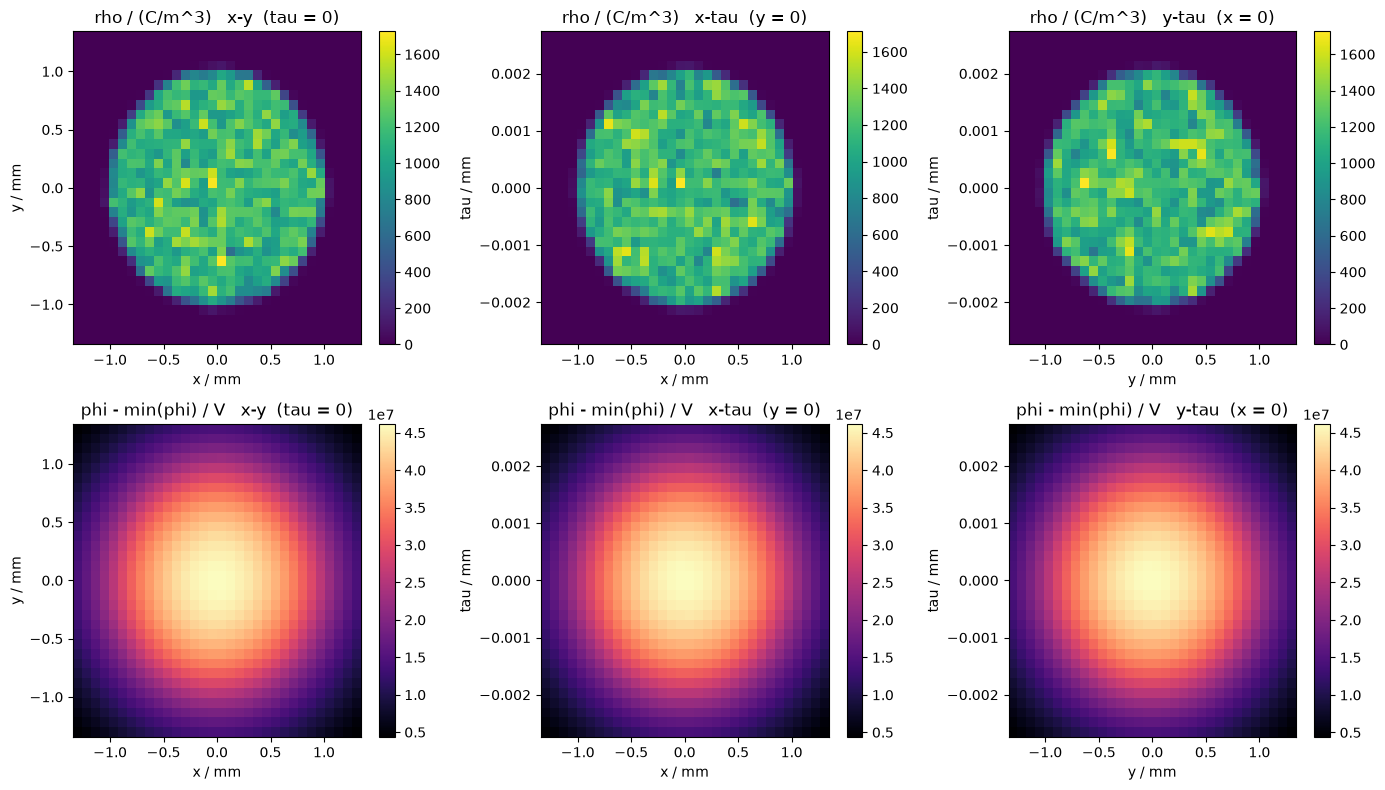

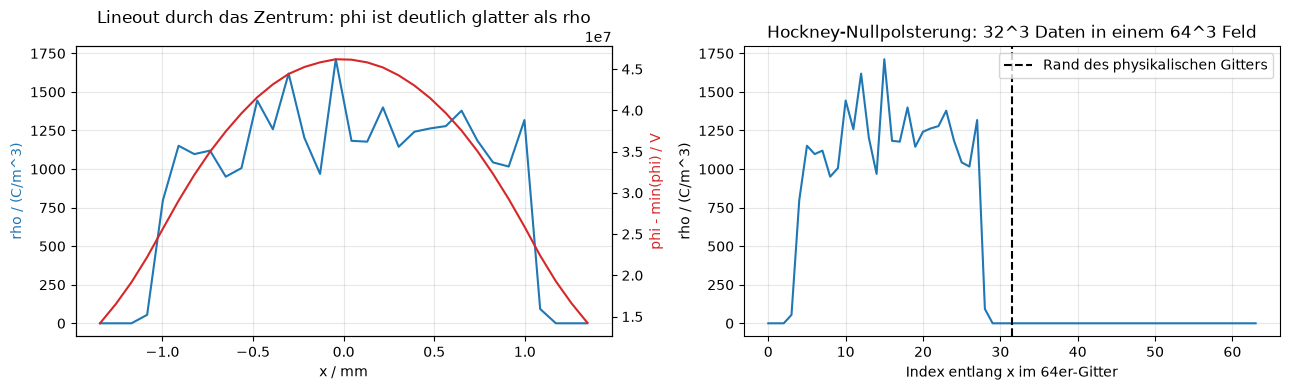

In [15]:
# rho und phi anschauen: Zentralschnitte durch das 32^3-Gitter
rho = probe["rho"][0].detach().numpy()
phi_np = (probe["phi"][0] - probe["phi"][0].min()).detach().numpy()  # Offset abgezogen
extent_mm = (probe["grid_dimensions"][0] * 1e3).detach().numpy()
nx, ny, ntau = kick.grid_shape
cx, cy, ct = nx // 2, ny // 2, ntau // 2

cuts = [
    ("x-y  (tau = 0)", (slice(None), slice(None), ct), (0, 1)),
    ("x-tau  (y = 0)", (slice(None), cy, slice(None)), (0, 2)),
    ("y-tau  (x = 0)", (cx, slice(None), slice(None)), (1, 2)),
]
labels = ["x / mm", "y / mm", "tau / mm"]

fig, axs = plt.subplots(2, 3, figsize=(14, 8))
for column, (title, index, (ia, ib)) in enumerate(cuts):
    for row, (field, name, cmap) in enumerate(
        [(rho, "rho / (C/m^3)", "viridis"), (phi_np, "phi - min(phi) / V", "magma")]
    ):
        ax = axs[row, column]
        image = ax.imshow(
            field[index].T,
            origin="lower",
            aspect="auto",
            cmap=cmap,
            extent=[-extent_mm[ia], extent_mm[ia], -extent_mm[ib], extent_mm[ib]],
        )
        fig.colorbar(image, ax=ax)
        ax.set_title(f"{name}   {title}")
        ax.set_xlabel(labels[ia])
        ax.set_ylabel(labels[ib])
fig.tight_layout()
plt.show()

fig, axs = plt.subplots(1, 2, figsize=(13, 4))

ax = axs[0]
axis_mm = torch.linspace(-extent_mm[0], extent_mm[0], nx).numpy()
ax.plot(axis_mm, rho[:, cy, ct], color="tab:blue")
ax.set_xlabel("x / mm")
ax.set_ylabel("rho / (C/m^3)", color="tab:blue")
twin = ax.twinx()
twin.plot(axis_mm, phi_np[:, cy, ct], color="tab:red")
twin.set_ylabel("phi - min(phi) / V", color="tab:red")
ax.set_title("Lineout durch das Zentrum: phi ist deutlich glatter als rho")
ax.grid(alpha=0.3)

ax = axs[1]
padded = probe["rho_padded"][0].detach().numpy()
ax.plot(padded[:, cy, ct])
ax.axvline(nx - 0.5, color="k", linestyle="--", label="Rand des physikalischen Gitters")
ax.set_xlabel("Index entlang x im 64er-Gitter")
ax.set_ylabel("rho / (C/m^3)")
ax.set_title("Hockney-Nullpolsterung: 32^3 Daten in einem 64^3 Feld")
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()


## Durchsicht 3 — An welcher Stelle hänge ich mein eigenes Modell ein?

**Antwort: `_solve_poisson_equation` überschreiben.** Das ist Schnitt A aus
`Surrogate Schnittstellen.md` — die Abbildung ρ ↦ φ, also genau die Blöcke 6 und 7
(Green-Funktion und FFT-Faltung). Alles andere bleibt klassischer Cheetah-Code.

Der Weg führt über eine **Unterklasse**, nicht über einen Fork des Elements. Damit erbt
man die gesamte Vektor-/Broadcast-Logik, das Koordinaten-Hin-und-Her und das
Impulsupdate unverändert; ersetzt wird ausschließlich der Löser.

| Schnitt | Methode zum Überschreiben | Eingang → Ausgang |
|---|---|---|
| **A** | `_solve_poisson_equation` | ρ (B,64,64,64) C/m³ → φ (B,32,32,32) V |
| B | `_E_plus_vB_field` | ρ → grad_x/y/tau, je (B,32,32,32) V/m; γ wird zwingend als Kanal gebraucht |
| C | `_compute_forces` | Positionen (B,N,3) → Kräfte (B,N,3) N |

Erste Probe ist die **Identität**: mit `solver=None` reicht die Unterklasse an die
Originalmethode durch und muss bitgleiche Teilchen liefern. Erst wenn das stimmt, sitzt
der Haken an der richtigen Stelle und nichts sonst wurde verändert.


In [16]:
class SurrogateSpaceChargeKick(cheetah.SpaceChargeKick):
    """`SpaceChargeKick` mit austauschbarem Poisson-Loeser -- Schnitt A: rho -> phi.

    Ueberschrieben wird ausschliesslich `_solve_poisson_equation`, also die Bloecke 6
    und 7 (Green-Funktion und FFT-Faltung). Deposition, Gradientenbildung,
    Rueckinterpolation, Impulsupdate und die gesamte Vektor-/Broadcast-Logik bleiben
    unveraendert der Originalcode.

    `solver=None` reicht an die Originalmethode durch -- die Identitaetsprobe.
    """

    def __init__(self, *args, solver=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.solver = solver

    def _solve_poisson_equation(
        self, beam, xp_coordinates, cell_size, grid_dimensions
    ):
        exact = super()._solve_poisson_equation(
            beam, xp_coordinates, cell_size, grid_dimensions
        )
        if self.solver is None:
            return exact
        rho = self._array_rho(beam, xp_coordinates, cell_size, grid_dimensions)
        # `exact` wird nur uebergeben, damit die Platzhalter unten kontrollierte
        # Fehler aufpraegen koennen. Ein echtes Modell rechnet allein aus rho.
        return self.solver(rho, cell_size, beam.relativistic_gamma, exact)


def build_segment(kick_factory):
    """Dasselbe Lattice wie oben, aber mit austauschbarem Kick-Typ."""
    return cheetah.Segment(
        elements=[
            cheetah.Drift(section_length / 6),
            kick_factory(section_length / 3, name="SC1"),
            cheetah.Drift(section_length / 3),
            kick_factory(section_length / 3, name="SC2"),
            cheetah.Drift(section_length / 3),
            kick_factory(section_length / 3, name="SC3"),
            cheetah.Drift(section_length / 6),
        ]
    )


segment_hook = build_segment(SurrogateSpaceChargeKick)
outgoing_hook = segment_hook.track(incoming)
print(
    "Identitaetsprobe -- Durchreiche bitgleich zum Original:",
    torch.equal(outgoing_hook.particles, outgoing.particles),
)


Identitaetsprobe -- Durchreiche bitgleich zum Original: True


In [17]:
# Zwei Platzhalter-Solver anstelle eines trainierten Netzes.
# Sie zeigen, dass der Haken greift -- und wie sich Feldfehler auf den Strahl auswirken.


class PerturbedSolver(torch.nn.Module):
    """Exaktes phi mit unkorreliertem Rauschen, relativ zur Streuung von phi."""

    def __init__(self, relative_error=0.01, seed=0):
        super().__init__()
        self.relative_error = relative_error
        self.generator = torch.Generator().manual_seed(seed)
        self.field_errors = []

    def forward(self, rho, cell_size, gamma, exact):
        centred = exact - exact.mean(dim=(-3, -2, -1), keepdim=True)
        noise = torch.randn(exact.shape, generator=self.generator, dtype=exact.dtype)
        predicted = exact + self.relative_error * centred.std() * noise
        self.field_errors.append(
            ((predicted - exact).norm() / centred.norm()).item()
        )
        return predicted


class TruncatedSolver(torch.nn.Module):
    """Behaelt nur die untersten `modes` Fourier-Moden von phi.

    Das ist genau die Operation, die eine Fourier-Schicht ausfuehrt. Damit laesst
    sich vorab abschaetzen, wie viele Moden das spaetere FNO braucht.
    """

    def __init__(self, modes=8):
        super().__init__()
        self.modes = modes
        self.field_errors = []

    def forward(self, rho, cell_size, gamma, exact):
        offset = exact.mean(dim=(-3, -2, -1), keepdim=True)
        centred = exact - offset
        spectrum = torch.fft.rfftn(centred, dim=(-3, -2, -1))
        keep = torch.zeros_like(spectrum)
        m = self.modes
        keep[..., :m, :m, :m] = spectrum[..., :m, :m, :m]
        keep[..., -m:, :m, :m] = spectrum[..., -m:, :m, :m]
        keep[..., :m, -m:, :m] = spectrum[..., :m, -m:, :m]
        keep[..., -m:, -m:, :m] = spectrum[..., -m:, -m:, :m]
        predicted = torch.fft.irfftn(keep, s=centred.shape[-3:], dim=(-3, -2, -1))
        self.field_errors.append(
            ((predicted - centred).norm() / centred.norm()).item()
        )
        return predicted + offset


def run_surrogate(solver, label):
    segment_surrogate = build_segment(
        lambda length, name: SurrogateSpaceChargeKick(length, solver=solver, name=name)
    )
    result = segment_surrogate.track(incoming)
    field_error = sum(solver.field_errors) / len(solver.field_errors)
    row = f"{label:26s} {field_error:14.4f}"
    for name in ["sigma_x", "sigma_px", "sigma_tau"]:
        a, b = getattr(outgoing, name), getattr(result, name)
        row += f" {((b - a) / a).item():14.2%}"
    print(row)
    return result


head = (
    f"{'Platzhalter-Solver':26s} {'phi rel. L2':>14s}"
    f" {'d sigma_x':>14s} {'d sigma_px':>14s} {'d sigma_tau':>14s}"
)
print(head)
print("-" * len(head))
run_surrogate(PerturbedSolver(relative_error=0.01), "1 % Rauschen")
run_surrogate(PerturbedSolver(relative_error=0.10), "10 % Rauschen")
for modes in [16, 8, 4]:
    run_surrogate(TruncatedSolver(modes=modes), f"nur {modes}^3 Fourier-Moden")

print(
    "\nAbweichungen beziehen sich auf den exakten Lauf oben."
    "\nUnkorreliertes Rauschen mittelt sich ueber 100 000 Teilchen weitgehend heraus;"
    "\nsystematische Fehler wie die Modenabschneidung tun das nicht --"
    "\ngenau der Unterschied, auf den es beim Surrogat ankommt."
)


Platzhalter-Solver            phi rel. L2      d sigma_x     d sigma_px    d sigma_tau
--------------------------------------------------------------------------------------
1 % Rauschen                       0.0100         -0.01%         -0.00%         -0.01%
10 % Rauschen                      0.1002          0.25%          1.01%          0.34%
nur 16^3 Fourier-Moden             0.0004          0.00%         -0.00%         -0.00%
nur 8^3 Fourier-Moden              0.0090          0.02%          0.05%          0.02%
nur 4^3 Fourier-Moden              0.0299         -0.25%         -0.46%         -0.17%

Abweichungen beziehen sich auf den exakten Lauf oben.
Unkorreliertes Rauschen mittelt sich ueber 100 000 Teilchen weitgehend heraus;
systematische Fehler wie die Modenabschneidung tun das nicht --
genau der Unterschied, auf den es beim Surrogat ankommt.


### Was daraus für die Pipeline folgt

- **Der Haken sitzt an einer Methode, nicht an einer Datei.** `SurrogateSpaceChargeKick`
  oben ist vollständig — mehr braucht es nicht, um später ein FNO einzusetzen. Der Solver
  bekommt ρ, `cell_size` und γ; das ist genau die Signatur, die in
  `Surrogate Schnittstellen.md` für Schnitt A festgehalten ist, und damit zugleich die
  Vorgabe dafür, wie die Trainingsdaten aus P4 aussehen müssen.
- **`exact` als viertes Argument ist nur ein Notebook-Hilfsmittel.** Ein echtes Modell
  bekommt es nicht — es rechnet aus ρ. Hier dient es dazu, kontrollierte Fehler
  aufzuprägen, ohne schon ein trainiertes Netz zu haben.
- **Die Modenabschneidung ist kein Spielzeug.** Sie ist genau die Operation, die eine
  Fourier-Schicht ausführt. Die Zahlen oben sind damit eine erste Auslegungshilfe für
  `k_max` — und die zugehörige Speicherrechnung (k_max³·d_v² komplexe Einträge pro
  Schicht) steht im `Motivationsleitfaden.md`.
- **φ ohne Mittelwert ist das Lernziel, nicht φ.** Die integrierte Green-Funktion ist nur
  bis auf eine Konstante bestimmt; der Offset trägt keine Physik, würde aber jede
  L2-Norm dominieren.
- **Implemented:** `scno.accelerator.NeuralSpaceChargeKick` takes exactly this
  subclass route, but overrides the grid-level `_solve_poisson_on_grid` (ρ on the
  unpadded grid, γ-stretched `cell_size`), so the vector/broadcast logic of the
  original comes for free.


## Leitfrage 5 — Wie ist das Gleichungssystem aufgebaut?

Cheetah löst **nicht** die Poisson-Gleichung im Strahlruhesystem mit anschließender
Lorentz-Rücktransformation (so macht es Ocelot), sondern eine modifizierte
Poisson-Gleichung direkt im Laborsystem. Vier Gleichungen, jeweils mit ihrer Codestelle:

**1. Modifizierte Poisson-Gleichung, gelöst als Faltung**

$$\phi \;=\; \frac{1}{4\pi\varepsilon_0}\,\rho * G
\;=\; \frac{1}{4\pi\varepsilon_0}\,\mathcal{F}^{-1}\!\big[\mathcal{F}(\rho)\cdot\mathcal{F}(G)\big]$$

`_solve_poisson_equation`. γ steckt ausschließlich in der Green-Funktion: in
`_integrated_green_function` wird die longitudinale Zellgröße als $d\tau = dz\cdot\gamma$
angesetzt. Diese Streckung tritt im Laborsystem an die Stelle der Lorentz-Transformation.

**2. Offene Ränder nach Hockney**

Die FFT-Faltung ist zyklisch, die Physik ist es nicht. Deshalb wird ρ auf das doppelte
Gitter genullpolstert (`_array_rho`), G in alle acht Oktanten gespiegelt, und nach der
Rücktransformation auf 32³ zurückgeschnitten. Preis: achtmal so viele Gitterpunkte, wie
physikalisch nötig wären — der Ansatzpunkt für die Hypothese aus dem
`Motivationsleitfaden.md`, dass der lokale W-Zweig eines FNO die offenen Ränder ohne
Polsterung trägt.

**3. Kraft aus dem Potential**

$$\vec F \;=\; q\,(\vec E + \vec v\times\vec B) \;=\; -\frac{e}{\gamma^{2}}\,\nabla\phi$$

`_E_plus_vB_field`, zentrale Differenzen mit Nullrand. Der Faktor $-1/\gamma^{2}$ ist die
magnetische Teilkompensation der elektrischen Abstoßung.

**4. Impulsupdate**

$$\Delta \vec p \;=\; \vec F\,\Delta t,\qquad \Delta t \;=\; \frac{L_\mathrm{eff}}{\beta c}$$

Positionen bleiben unverändert — deshalb muss der Kick im Lattice mit Drifts verschränkt
werden (Zelle oben), sonst bewegt sich nichts.

Die folgende Zelle rechnet (3) direkt nach und prüft die γ-Abhängigkeit aus (1) über
vier Energien.


In [18]:
# (3) F_x/e = -1/gamma^2 * dphi/dx von Hand nachgerechnet
phi_t = probe["phi"]
gamma_probe = probe["gamma"]
manual_grad = torch.zeros_like(phi_t)
manual_grad[..., 1:-1, :, :] = (phi_t[..., 2:, :, :] - phi_t[..., :-2, :, :]) * (
    0.5 / probe["cell_size"][..., 0, None, None, None]
)
manual_grad = -manual_grad / gamma_probe[..., None, None, None] ** 2
relative_difference = (
    (manual_grad - probe["grad_x"]).abs().max() / probe["grad_x"].abs().max()
).item()
print(
    f"(3) F_x/e = -1/gamma^2 * dphi/dx nachgerechnet:"
    f" max. rel. Abweichung {relative_difference:.2e}\n"
)

# (1) Wo gamma eingeht: derselbe Bunch (im Ruhesystem) bei vier Energien
print("(1) Wo gamma eingeht -- derselbe Bunch bei vier Energien:\n")
head = (
    f"{'Energie / eV':>13s} {'gamma':>9s} {'phi-Spanne / V':>16s}"
    f" {'/ (gamma*phi_0)':>16s} {'|grad_x|max V/m':>16s} {'* gamma':>12s}"
)
print(head)
print("-" * len(head))
for test_energy in [1e6, 1e7, 1e8, 2.5e8]:
    energy_tensor = torch.tensor(test_energy)
    test_gamma = energy_tensor / REST_ENERGY
    test_beta = (1 - test_gamma.square().reciprocal()).sqrt()
    torch.manual_seed(0)
    test_beam = cheetah.ParticleBeam.uniform_3d_ellipsoid(
        num_particles=20_000,
        total_charge=TOTAL_CHARGE,
        energy=energy_tensor,
        radius_x=R0,
        radius_y=R0,
        radius_tau=R0 / test_gamma / test_beta,  # Laborsystem: um gamma gestaucht
        sigma_px=torch.tensor(1e-15),
        sigma_py=torch.tensor(1e-15),
        sigma_p=torch.tensor(1e-15),
    )
    test_probe = probe_space_charge(kick, test_beam)
    span = (test_probe["phi"].max() - test_probe["phi"].min()).item()
    g = test_probe["gamma"].item()
    grad_max = test_probe["grad_x"].abs().max().item()
    print(
        f"{test_energy:13.3e} {g:9.2f} {span:16.4e} {span / (g * phi_sphere):16.3f}"
        f" {grad_max:16.4e} {grad_max * g:12.4e}"
    )

print(
    "\nphi-Spanne waechst wie gamma (Stauchung im Laborsystem),"
    "\n|grad_x| faellt wie 1/gamma (Faktor -1/gamma^2 gegen die gamma-fache Steigung)."
    "\nDas ist die Raumladungsunterdrueckung mit der Energie, in Zahlen."
)


(3) F_x/e = -1/gamma^2 * dphi/dx nachgerechnet: max. rel. Abweichung 9.12e-08

(1) Wo gamma eingeht -- derselbe Bunch bei vier Energien:

 Energie / eV     gamma   phi-Spanne / V  / (gamma*phi_0)  |grad_x|max V/m      * gamma
---------------------------------------------------------------------------------------
    1.000e+06      1.96       1.8941e+05            1.077       4.3516e+07   8.5158e+07
    1.000e+07     19.57       1.8531e+06            1.054       4.3523e+06   8.5172e+07
    1.000e+08    195.70       1.8528e+07            1.053       4.3521e+05   8.5169e+07
    2.500e+08    489.24       4.6320e+07            1.053       1.7408e+05   8.5169e+07

phi-Spanne waechst wie gamma (Stauchung im Laborsystem),
|grad_x| faellt wie 1/gamma (Faktor -1/gamma^2 gegen die gamma-fache Steigung).
Das ist die Raumladungsunterdrueckung mit der Energie, in Zahlen.


## Antworten, festgehalten

**Durchsicht 1 — Was rechnet ein Space-Charge-Kick?**
Elf Blöcke, aufgerufen von außen nach innen, Daten fließen umgekehrt. Deposition der
Makroteilchen auf ein 32³-Gitter bei ±3σ (trilinear, Ladung bleibt hier zu 100 % auf
dem Gitter, weil ein uniformes Ellipsoid vollständig innerhalb ±3σ liegt) → Division
durch das Zellvolumen und Nullpolsterung auf 64³ → Aufbau der integrierten
Green-Funktion auf 64³ mit longitudinal γ-gestreckter Zelle → FFT-Faltung, Rückschnitt
auf 32³ → zentrale Differenzen mit Faktor −1/γ² → trilineare Rückinterpolation auf die
Teilchen → Δp = F·Δt. Belegt: das von Hand zusammengesetzte Ergebnis ist bitgleich mit
`kick.track`. φ trägt dabei einen willkürlichen additiven Offset (hier ≈ 1,95·10⁷ V bei
einer Spannweite von 4,62·10⁷ V) — die integrierte Green-Funktion ist nur bis auf eine
Konstante bestimmt. Für ein Surrogat heißt das: nicht φ selbst ist das Lernziel,
sondern φ ohne Mittelwert.

**Durchsicht 3 — Wo hängt das eigene Modell ein?**
`_solve_poisson_equation` in einer Unterklasse von `SpaceChargeKick` überschreiben
(Schnitt A, ρ ↦ φ). Die Durchreiche-Variante liefert bitgleiche Teilchen, der Haken
sitzt also sauber. Signatur für das Netz: ρ (B,64,64,64) in C/m³, `cell_size` (B,3) in m,
γ (B,) → φ (B,32,32,32) in V. Ausbaustufen: `_E_plus_vB_field` (Schnitt B),
`_compute_forces` (Schnitt C).
Erste Auslegungszahl aus dem Modentest: 8³ Fourier-Moden reichen für ~0,9 % Feldfehler
und ~0,05 % Abweichung in σ_px, 4³ Moden für ~3 % Feldfehler und ~0,5 % in σ_px.
Nebenbefund: unkorreliertes Rauschen auf φ mittelt sich über 100 000 Teilchen fast
vollständig heraus (1 % Feldfehler → 0,01 % in σ), systematische Fehler wie die
Modenabschneidung nicht. Feldfehler allein ist damit kein taugliches Gütemaß.

**Leitfrage 5 — Wie ist das Gleichungssystem aufgebaut?**
Modifizierte Poisson-Gleichung im **Laborsystem**, gelöst als Faltung ρ ∗ G mit
Hockney-Nullpolsterung für offene Ränder; γ geht ausschließlich über dτ = dz·γ in die
Green-Funktion ein. Kraft F = −(e/γ²)·∇φ, nachgerechnet auf 9·10⁻⁸ relative Abweichung.
Impuls-Update Δp = F·Δt mit Δt = L_eff/(βc), Positionen unverändert.
Die γ-Skalierung ist über vier Energien (1 MeV bis 250 MeV, γ = 1,96 … 489) sauber
bestätigt: die φ-Spannweite wächst wie γ und trifft die Erwartung γ·Q/(4πε₀R₀) auf
5 % genau, während |∇φ|·(1/γ²) wie 1/γ fällt — das Produkt |grad_x|·γ ist über alle
vier Energien konstant bei 8,52·10⁷ V/m. Das ist die Raumladungsunterdrückung mit der
Energie, in Zahlen.


# Profiling von SpaceChargeKick

## Messumgebung

In [21]:
import gc
import platform
#import resource

import pandas as pd
import torch
from torch.profiler import ProfilerActivity, profile, record_function
from torch.utils.benchmark import Timer

DEVICES = ["cpu"] + (["cuda"] if torch.cuda.is_available() else [])
GRIDS = [(32, 32, 32), (64, 64, 64)]

print(f"{platform.processor()} | torch {torch.__version__}")
for d in DEVICES:
    if d == "cuda":
        print(f"GPU: {torch.cuda.get_device_name(0)}, "
              f"{torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GiB")

Intel64 Family 6 Model 142 Stepping 12, GenuineIntel | torch 2.14.0+cpu


## Unterklasse von SpaceChargeKick mit Messblöcken

In [22]:
class ProfiledSpaceChargeKick(cheetah.SpaceChargeKick):
    """`SpaceChargeKick` with a `record_function` marker around each block.

    The grid-level solve is its own method (`_solve_poisson_on_grid`), so nothing
    has to be re-implemented: "B6 Green-Aufbau" marks the Green function and
    "B6-7 Green + FFT" the whole grid-level solve. The net FFT time is the
    difference of the two.
    """

    def _array_rho(self, beam, xp, cell_size, grid_dimensions):
        with record_function("B4-5 Deposition"):
            return super()._array_rho(beam, xp, cell_size, grid_dimensions)

    def _integrated_green_function(self, cell_size, grid_shape):
        with record_function("B6 Green-Aufbau"):
            return super()._integrated_green_function(cell_size, grid_shape)

    def _solve_poisson_on_grid(self, charge_density, cell_size):
        with record_function("B6-7 Green + FFT"):
            return super()._solve_poisson_on_grid(charge_density, cell_size)

    def _E_plus_vB_field(self, beam, xp, cell_size, grid_dimensions):
        with record_function("B8 Differenzen"):
            return super()._E_plus_vB_field(beam, xp, cell_size, grid_dimensions)

    def _compute_forces(self, beam, xp, cell_size, grid_dimensions):
        with record_function("B9 Interpolation"):
            return super()._compute_forces(beam, xp, cell_size, grid_dimensions)

    def track(self, incoming):
        with record_function("track gesamt"):
            return super().track(incoming)


# Cross-check: the markers must not change the result
_check = ProfiledSpaceChargeKick(section_length / 3, name="chk").track(incoming)
print("bit-identical to the original:",
      torch.equal(_check.particles, kick.track(incoming).particles))


bitgleich zum Original: True


## Profiling Zeit
### Vorwärtslauf

In [24]:
BLOCKS = ["B4-5 Deposition", "B6 Green-Aufbau", "B6-7 Green + FFT",
          "B8 Differenzen", "B9 Interpolation"]


def profile_track(num_particles, grid, device):
    beam = make_beam(num_particles, device)      # siehe Zelle 10, nur mit .to(device)
    beam.particles.requires_grad_(True)
    kick = ProfiledSpaceChargeKick(section_length / 3, grid_shape=grid, name="SC")

    out = kick.track(beam)                        # Aufwärmrunde, nicht mitzählen
    out.sigma_x.backward()
    beam.particles.grad = None

    activities = [ProfilerActivity.CPU]
    if device.startswith("cuda"):
        activities.append(ProfilerActivity.CUDA)
        torch.cuda.synchronize()

    with profile(activities=activities, profile_memory=True) as prof:
        with record_function("VORWAERTS"):
            out = kick.track(beam)
            loss = out.sigma_x
            if device.startswith("cuda"):
                torch.cuda.synchronize()
        with record_function("RUECKWAERTS"):
            loss.backward()
            if device.startswith("cuda"):
                torch.cuda.synchronize()

    events = {e.key: e for e in prof.key_averages()}

    def ms(key):
        e = events.get(key)
        if e is None:
            return float("nan")
        raw = e.device_time_total if device.startswith("cuda") else e.cpu_time_total
        return raw / 1e3

    dep, green, solve, diff, interp = (ms(b) for b in BLOCKS)
    total = ms("track gesamt")
    return {
        "Deposition": dep,
        "Green-Aufbau": green,
        "FFT-Faltung": solve - green,
        "Differenzen": diff - dep - solve,
        "Interpolation": interp - diff,
        "Koordinaten + Kick": total - interp,
        "vorwaerts": ms("VORWAERTS"),
        "rueckwaerts": ms("RUECKWAERTS"),
    }, prof


row, prof = profile_track(100_000, (32, 32, 32), "cpu")
print(prof.key_averages().table(sort_by="self_cpu_time_total", row_limit=20))
prof.export_chrome_trace("sc_trace_32_cpu.json")   # für die Abbildung


NameError: name 'make_beam' is not defined

### Rückwärtslauf

In [ ]:
def bench_block(label, fn, inputs, min_run_time=1.0):
    """Wandzeit vorwärts und rückwärts für einen einzelnen Block."""
    for t in inputs:
        t.requires_grad_(True)

    t_fwd = Timer(stmt="fn()", globals={"fn": fn}) \
        .blocked_autorange(min_run_time=min_run_time).median * 1e3

    out = fn()
    scalar = out.sum() if torch.is_tensor(out) else sum(o.sum() for o in out)
    t_bwd = Timer(
        stmt="torch.autograd.grad(scalar, inputs, retain_graph=True)",
        globals={"torch": torch, "scalar": scalar, "inputs": inputs},
    ).blocked_autorange(min_run_time=min_run_time).median * 1e3

    print(f"{label:22s} vorwaerts {t_fwd:8.2f} ms   rueckwaerts {t_bwd:8.2f} ms"
          f"   Verhaeltnis {t_bwd / t_fwd:5.2f}")
    return t_fwd, t_bwd


flat, xp = probe["flat"], probe["xp_coordinates"].detach()
cell_size, grid_dimensions = probe["cell_size"], probe["grid_dimensions"]
rho, green = probe["rho_padded"].detach(), probe["green"].detach()

bench_block("Deposition",
            lambda: kick._array_rho(flat, xp, cell_size, grid_dimensions), [xp])
stretched_cell_size = probe["stretched_cell_size"].detach()
bench_block("Green-Aufbau",
            lambda: kick._integrated_green_function(stretched_cell_size, kick.grid_shape),
            [stretched_cell_size])
bench_block("FFT-Faltung", lambda: torch.fft.irfftn(
    torch.fft.rfftn(rho, dim=[1, 2, 3]) * torch.fft.rfftn(green, dim=[1, 2, 3]),
    dim=[1, 2, 3]).real, [rho, green])
bench_block("Poisson gesamt",
            lambda: kick._solve_poisson_equation(flat, xp, cell_size, grid_dimensions), [xp])
bench_block("+ Differenzen",
            lambda: kick._E_plus_vB_field(flat, xp, cell_size, grid_dimensions), [xp])
bench_block("+ Interpolation",
            lambda: kick._compute_forces(flat, xp, cell_size, grid_dimensions), [xp])


## Profiling Speicher

In [ ]:
def peak_memory_mib(fn, device):
    """Spitzenspeicher eines Aufrufs. GPU exakt, CPU über die Prozess-Höchstmarke."""
    gc.collect()
    if device.startswith("cuda"):
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        fn()
        torch.cuda.synchronize()
        return torch.cuda.max_memory_allocated() / 2**20
    before = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024
    fn()
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024 - before


### Subprocess für Speicherprofiling

In [ ]:
import json
import subprocess
import sys

SNIPPET = """
import json, resource, sys, torch
sys.path.insert(0, ".")
from sc_profiling import make_beam, build_kick     # ausgelagerte Hilfsfunktionen
n, g = int(sys.argv[1]), int(sys.argv[2])
beam = make_beam(n, "cpu"); beam.particles.requires_grad_(True)
kick = build_kick((g, g, g))
out = kick.track(beam); out.sigma_x.backward()
print(json.dumps({"peak_mib": resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024}))
"""


def peak_memory_subprocess(num_particles, grid_edge):
    result = subprocess.run(
        [sys.executable, "-c", SNIPPET, str(num_particles), str(grid_edge)],
        capture_output=True, text=True, check=True)
    return json.loads(result.stdout.strip().splitlines()[-1])["peak_mib"]


## Profiltabelle

In [ ]:
rows = []
for device in DEVICES:
    for grid in GRIDS:
        for n in [10_000, 100_000, 1_000_000]:
            row, _ = profile_track(n, grid, device)
            row.update(Geraet=device, Gitter=f"{grid[0]}³", N=n)
            row["Spitzenspeicher / MiB"] = (
                peak_memory_mib(lambda: profile_track(n, grid, device), device)
                if device.startswith("cuda")
                else peak_memory_subprocess(n, grid[0]))
            rows.append(row)

profiltabelle = pd.DataFrame(rows).set_index(["Geraet", "Gitter", "N"])
profiltabelle.round(2).to_csv("profiltabelle_p2.csv")
profiltabelle.round(2)


## Bild zu Speicherverlauf (nur für GPU)

In [ ]:
torch.cuda.memory._record_memory_history(max_entries=100_000)
out = kick.track(beam)
out.sigma_x.backward()
torch.cuda.memory._dump_snapshot("sc_memory_32_cuda.pickle")
torch.cuda.memory._record_memory_history(enabled=None)
# Datei auf https://pytorch.org/memory_viz hochladen -> Zeitstrahl der Belegung


# Datenladeroutine

In [ ]:
def load_rho_phi()

In [ ]:
train_loader, test_loaders, data_processor = load_rho_phi(
    n_train=1000,
    batch_size=64,
    n_tests=[100, 50],
    test_resolutions=[16, 32, 64],
    test_batch_sizes=[32, 32],
)
data_processor = data_processor.to(device)